<a href="https://colab.research.google.com/github/pskh2004/Water_Quality_EDA/blob/main/Amirparsa_Khoshnoud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis (EDA) - Water Potability Dataset

## Overview
This notebook conducts a rigorous **Exploratory Data Analysis (EDA)** on the [Water Potability](https://www.kaggle.com/datasets/adityakadiwal/water-potability/data) dataset. The ultimate goal of analyzing this dataset is to understand the biophysical and chemical characteristics of water samples and determine if they are safe for human consumption (**Potability**).

## Key Objectives
1. **Data Integrity & Missing Value Evaluation:** Analyze the presence and distribution of missing values across features like `ph`, `Sulfate`, and `Trihalomethanes` and determine the trade-offs of handling them.
2. **Univariate Feature Analysis:** Map out distributions, skewness, noise, and outliers for each of the 9 water quality metrics.
3. **Multivariate & Correlation Investigation:** Inspect pairwise feature relationships using interactive/static scatter plots and correlation matrices to identify predictive patterns.

## Summary of Key Insights from EDA
* **Missing Values Impact:** Approximately **38.6% of the samples (1,265 rows)** contain at least one missing value. Completely dropping these records leaves 2,011 complete rows.
* **Feature Distributions:** Most physical/chemical properties (like `ph`, `Hardness`, `Chloramines`, `Sulfate`, `Organic_carbon`, `Trihalomethanes`, and `Turbidity`) closely follow a **normal distribution** with varying degrees of noise and localized outliers. `Solids` and `Conductivity` exhibit noticeable **positive skewness**.
* **Imbalanced Target:** The target variable `Potability` is imbalanced, with fewer drinkable (potable) samples than non-potable ones.
* **Statistical Independence:** Pairwise scatter plots (including a 3D visualization) and the correlation matrix confirm that **there are virtually no linear or non-linear correlations** between the features. Features act as statistically independent variables, implying that simple linear classifiers might struggle and more robust non-linear models may be needed.

This notebook contains EDA for the ***[Water Portability](https://www.kaggle.com/datasets/adityakadiwal/water-potability/data)*** dataset in Kaggle

**Downloading Dependencies**

In [ ]:
!pip install Ipython

**Importing Libraries & dataset**

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("adityakadiwal/water-potability")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'water-potability' dataset.
Path to dataset files: /kaggle/input/water-potability


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno
import seaborn as sns

In [ ]:
data= pd.read_csv("/kaggle/input/water-potability/water_potability.csv")
df= pd.DataFrame(data)


In [ ]:
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [ ]:
df.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


**Handling Missing Value**

In [ ]:
df.isna().sum()

,0
ph,491
Hardness,0
Solids,0
Chloramines,0
Sulfate,781
Conductivity,0
Organic_carbon,0
Trihalomethanes,162
Turbidity,0
Potability,0


In [ ]:
def describe(df):


    variables = []
    dtypes = []
    count = []
    unique = []
    missing = []
    Missing_percentage=[]

    for columns in df.columns:
        variables.append(columns)
        dtypes.append(df[columns].dtype)
        count.append(len(df[columns]))
        unique.append(len(df[columns].unique()))
        missing.append(df[columns].isna().sum())
        missing_data_percentage= (df[columns].isna().sum()/len(df))*100
        Missing_percentage.append(f"{missing_data_percentage:.2f}%")

    output = pd.DataFrame({
        'Variable': variables,
        'Data type': dtypes,
        'Count': count,
        'Unique': unique,
        'Missing value': missing,
        'Missing Ratio': Missing_percentage
    })

    return output

In [ ]:
describe(df)

,Variable,Data type,Count,Unique,Missing value,Missing Ratio
0,ph,float64,3276,2786,491,14.99%
1,Hardness,float64,3276,3276,0,0.00%
2,Solids,float64,3276,3276,0,0.00%
3,Chloramines,float64,3276,3276,0,0.00%
4,Sulfate,float64,3276,2496,781,23.84%
5,Conductivity,float64,3276,3276,0,0.00%
6,Organic_carbon,float64,3276,3276,0,0.00%
7,Trihalomethanes,float64,3276,3115,162,4.95%
8,Turbidity,float64,3276,3276,0,0.00%
9,Potability,int64,3276,2,0,0.00%


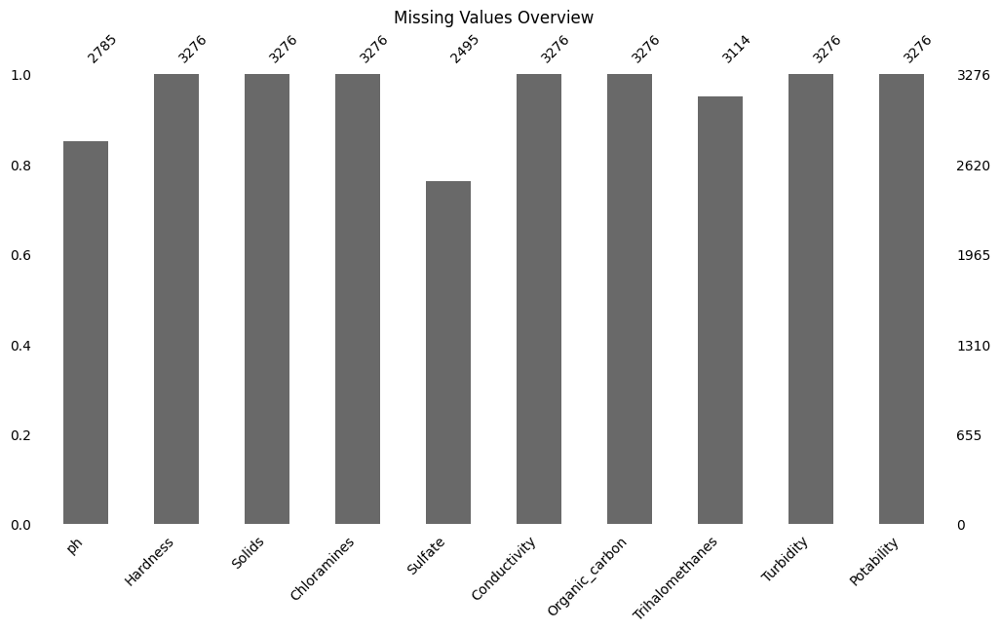

In [ ]:
msno.bar(df, figsize=(12, 6), fontsize=10)
plt.title("Missing Values Overview")
plt.show()

Checking overlap possibility

In [ ]:
rows_with_missing = df.isna().any(axis=1).sum()
print(rows_with_missing)

1265


In [ ]:
from IPython.display import display
rows_with_NaN= df[df.isna().any(axis=1)]
display(rows_with_NaN)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
8,NaN,118.988579,14285.583854,7.804174,268.646941,389.375566,12.706049,53.928846,3.595017,0
11,7.974522,218.693300,18767.656682,8.110385,NaN,364.098230,14.525746,76.485911,4.011718,0
...,...,...,...,...,...,...,...,...,...,...
3266,8.372910,169.087052,14622.745494,7.547984,NaN,464.525552,11.083027,38.435151,4.906358,1
3272,7.808856,193.553212,17329.802160,8.061362,NaN,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,NaN,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,NaN,402.883113,11.168946,77.488213,4.708658,1


In [ ]:
df.shape

(3276, 10)

In [ ]:
new_df=df.dropna()
new_df.isna().sum()

,0
ph,0
Hardness,0
Solids,0
Chloramines,0
Sulfate,0
Conductivity,0
Organic_carbon,0
Trihalomethanes,0
Turbidity,0
Potability,0


In [ ]:
new_df.shape

(2011, 10)

There is no overlap in missing values

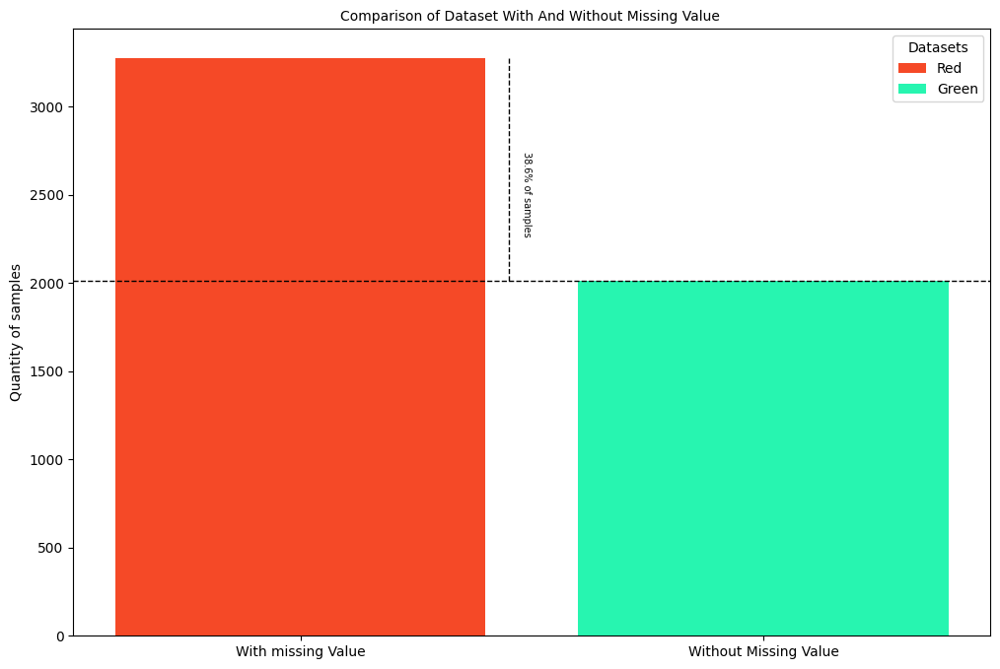

In [ ]:

fig, ax = plt.subplots( figsize=(12,8)  ,dpi=100)

datasets = ['With missing Value', 'Without Missing Value']
counts = [3276, 2011]
bar_labels = ['Red', 'Green']
bar_colors = ['#F54927', '#27F5B0']

ax.bar(datasets, counts, label=bar_labels, color=bar_colors)
ax.axhline(
    y=2011,
    color='black',
    linestyle='--',
    linewidth=1,

)

ax.vlines(
    x=0.45,
    ymin=2011,
    ymax=3276,
    color='black',
    linestyle='--',
    linewidth=1,
)
ax.text(
    0.50,
    2500,
    '38.6% of samples',
    rotation=270,
    va='center',
    ha='right',
    fontsize=7
)
ax.set_ylabel('Quantity of samples' , fontsize=10)
ax.set_title('Comparison of Dataset With And Without Missing Value ' , fontsize=10)
ax.legend(title='Datasets')

plt.show()

In handling missing value process we have deleted ***1265 rows*** of total ***3267 rows*** which is nearly ***39%*** of dataset, which is a large amount.

**Visualization**

*   Distributions
*   Scatter plots
*   Correlation heatmap


**Distributions**

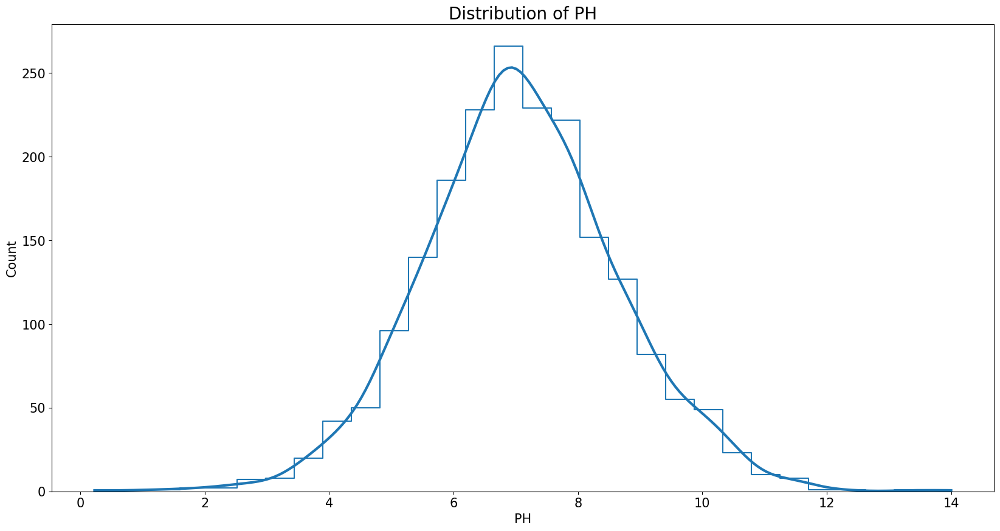

In [ ]:
fig, ax = plt.subplots(figsize=(20, 10), dpi=100)


sns.histplot(
        data=new_df,
        x="ph",
        bins=30,
        #color="#F54927",
        kde=True,
        line_kws={
        'color': "#27F5B0",
        'linewidth': 3
        },
        ax=ax,

        element='step',
        fill=False

    )

ax.set_title("Distribution of PH", fontsize=20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
ax.set_xlabel('PH', fontsize=15)
ax.set_ylabel('Count', fontsize=15)


plt.show()

This plot shows that Ph has ***normal distribution*** and the most amount of samples are in the range between 6 & 8.

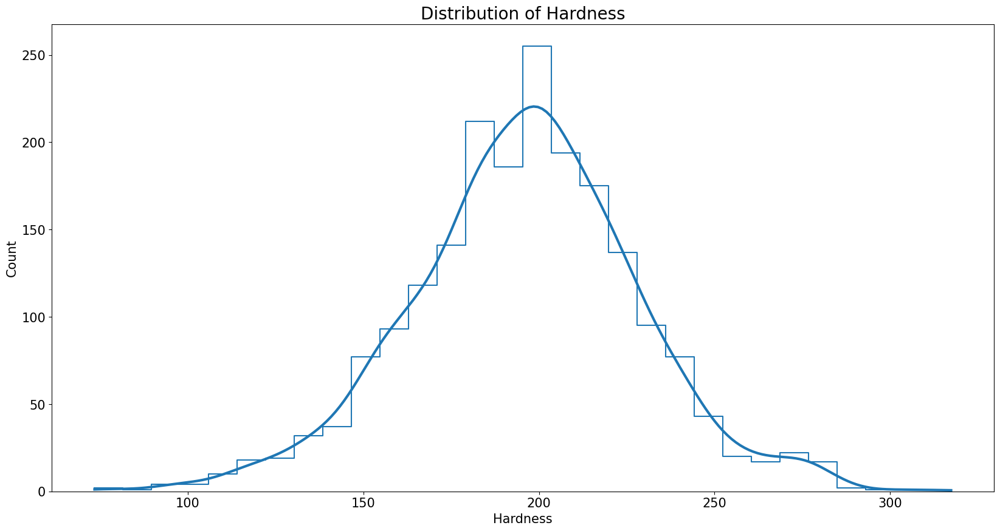

In [ ]:
fig, ax = plt.subplots(figsize=(20, 10), dpi=100)


sns.histplot(
        data=new_df,
        x="Hardness",
        bins=30,
        #color="#F54927",
        kde=True,
        line_kws={
        'color': "#27F5B0",
        'linewidth': 3
        },
        ax=ax,

        element='step',
        fill=False

    )

ax.set_title("Distribution of Hardness", fontsize=20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
ax.set_xlabel('Hardness', fontsize=15)
ax.set_ylabel('Count', fontsize=15)


plt.show()

THis plot represents that Hardness has ***normal distribution***, but it can be seen that we may face outliers and noise.

 ***Outliers*** between 250 and 300 as we see shoulders.

  ***Noises*** in peak of the distribution.

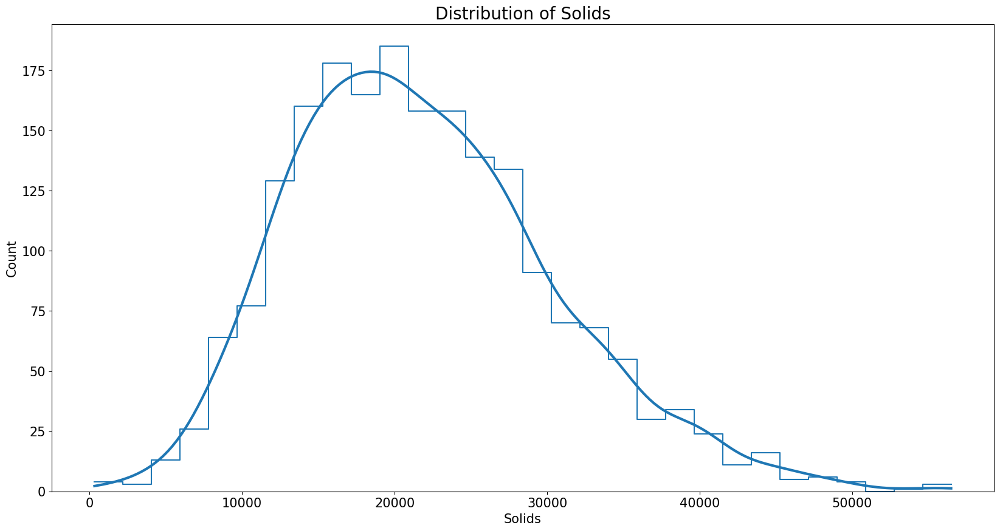

In [ ]:
fig, ax = plt.subplots(figsize=(20, 10), dpi=100)


sns.histplot(
        data=new_df,
        x="Solids",
        bins=30,
        #color="#F54927",
        kde=True,
        line_kws={
        'color': "#27F5B0",
        'linewidth': 3
        },
        ax=ax,

        element='step',
        fill=False

    )

ax.set_title("Distribution of Solids", fontsize=20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
ax.set_xlabel('Solids', fontsize=15)
ax.set_ylabel('Count', fontsize=15)


plt.show()

Distribution of solids illustrates the ***positive skewness*** in its distribution.

So it has ***outliers*** in Solids>50000 which is noticable by differences between KDE line and bar.

And we can see sawtooth in the peak so it can be ***noise***

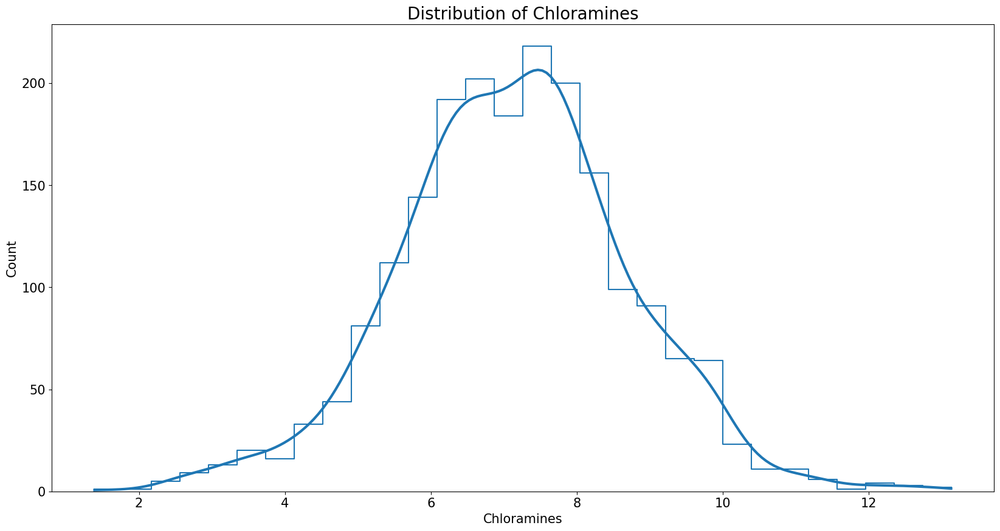

In [ ]:
fig, ax = plt.subplots(figsize=(20, 10), dpi=100)


sns.histplot(
        data=new_df,
        x="Chloramines",
        bins=30,
        #color="#F54927",
        kde=True,
        line_kws={
        'color': "#27F5B0",
        'linewidth': 3
        },
        ax=ax,

        element='step',
        fill=False

    )

ax.set_title("Distribution of Chloramines", fontsize=20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
ax.set_xlabel('Chloramines', fontsize=15)
ax.set_ylabel('Count', fontsize=15)


plt.show()

This plot informs nearly ***normal distribution*** of Chloramines which we can't see noticable shoulders to detect ***outliers***, but the **M** shape at the peak shows us the possible ***noise***

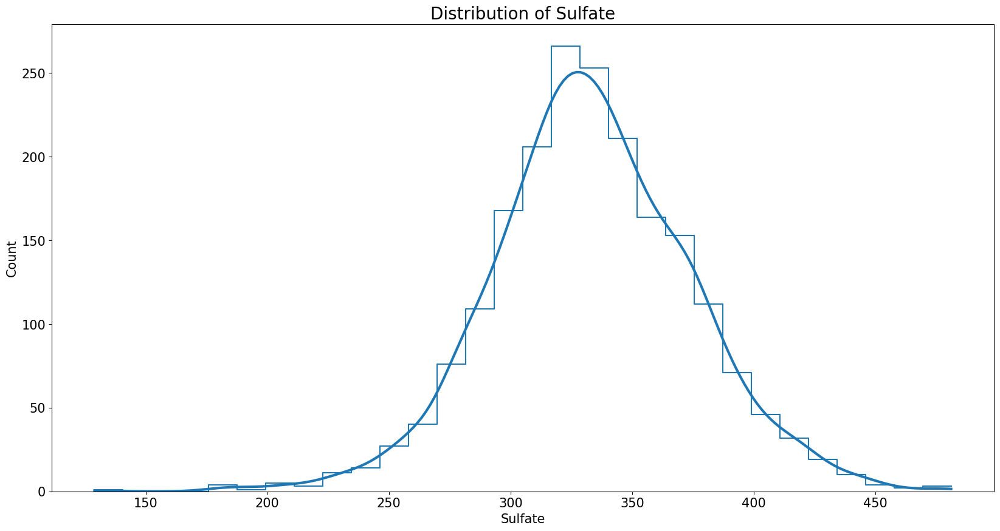

In [ ]:
fig, ax = plt.subplots(figsize=(20, 10), dpi=100)


sns.histplot(
        data=new_df,
        x="Sulfate",
        bins=30,
        #color="#F54927",
        kde=True,
        line_kws={
        'color': "#27F5B0",
        'linewidth': 3
        },
        ax=ax,

        element='step',
        fill=False

    )

ax.set_title("Distribution of Sulfate", fontsize=20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
ax.set_xlabel('Sulfate', fontsize=15)
ax.set_ylabel('Count', fontsize=15)


plt.show()

Sulfate distribution plot illustrates that it has ***no*** noticable ***outliers*** and ***noise***.

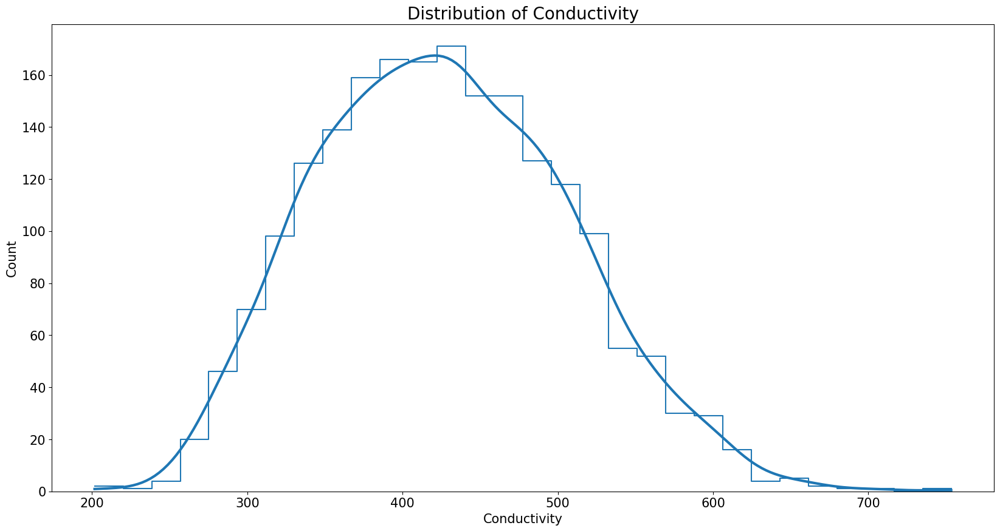

In [ ]:
fig, ax = plt.subplots(figsize=(20, 10), dpi=100)


sns.histplot(
        data=new_df,
        x="Conductivity",
        bins=30,
        #color="#F54927",
        kde=True,
        line_kws={
        'color': "#27F5B0",
        'linewidth': 3
        },
        ax=ax,

        element='step',
        fill=False

    )

ax.set_title("Distribution of Conductivity", fontsize=20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
ax.set_xlabel('Conductivity', fontsize=15)
ax.set_ylabel('Count', fontsize=15)


plt.show()

It's obvious that we're facing ***positive skewness*** in Conductivity's distribution.

It has two suspicious ***outliers*** near 200 and 700.

We can see a sudden decrease in counts in the peak (near x=450-460), it can be concluded as ***noise*** detection.

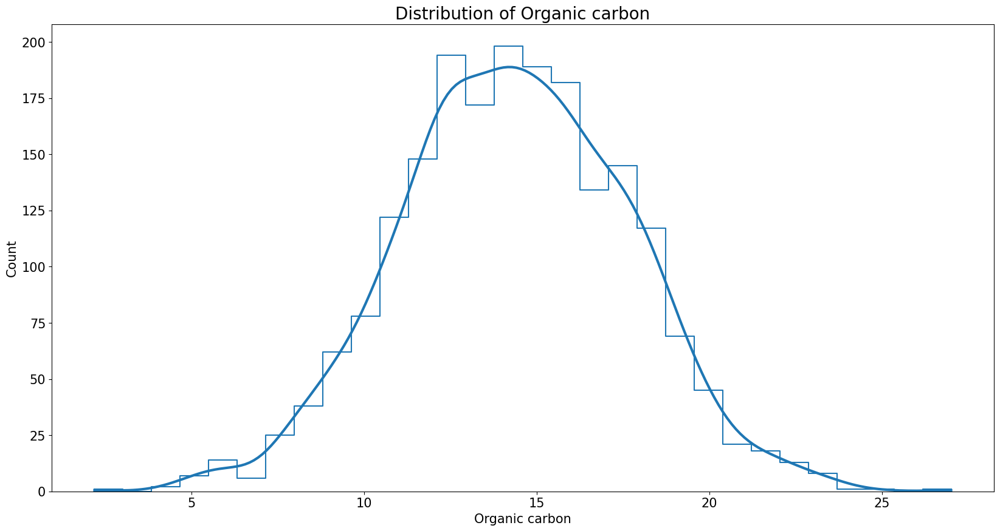

In [ ]:
fig, ax = plt.subplots(figsize=(20, 10), dpi=100)


sns.histplot(
        data=new_df,
        x="Organic_carbon",
        bins=30,
        #color="#F54927",
        kde=True,
        line_kws={
        'color': "#27F5B0",
        'linewidth': 3
        },
        ax=ax,

        element='step',
        fill=False

    )

ax.set_title("Distribution of Organic carbon", fontsize=20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
ax.set_xlabel('Organic carbon', fontsize=15)
ax.set_ylabel('Count', fontsize=15)


plt.show()

This is ***normal distribution***

We can see the shoulder in between 0<x<5 and it represents ***outliers***.

And ***noise*** is noticable by sawtooth in the peak.

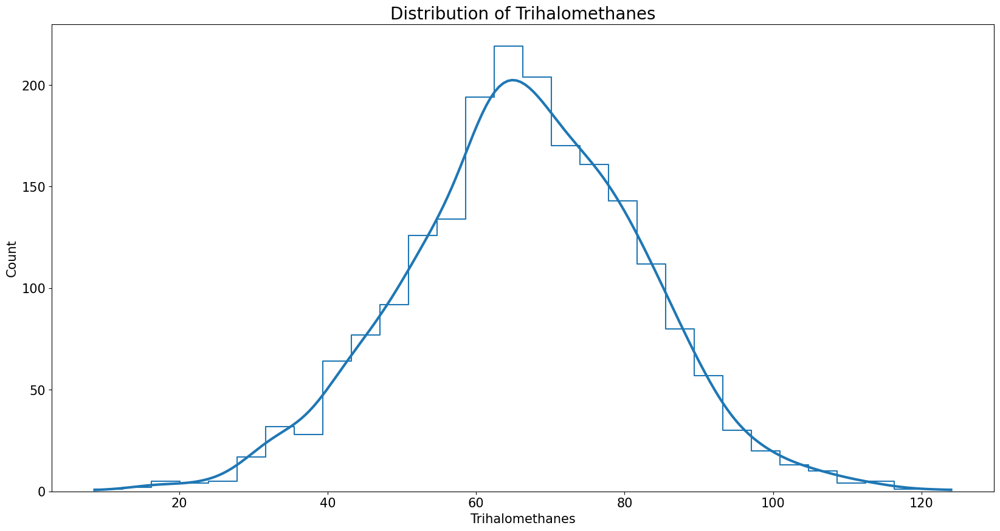

In [ ]:
fig, ax = plt.subplots(figsize=(20, 10), dpi=100)


sns.histplot(
        data=new_df,
        x="Trihalomethanes",
        bins=30,
        #color="#F54927",
        kde=True,
        line_kws={
        'color': "#27F5B0",
        'linewidth': 3
        },
        ax=ax,

        element='step',
        fill=False

    )

ax.set_title("Distribution of Trihalomethanes", fontsize=20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
ax.set_xlabel('Trihalomethanes', fontsize=15)
ax.set_ylabel('Count', fontsize=15)


plt.show()

This distribution can be called ***normal distribution***.

It has ***outliers*** in 0<x<20

It has a sharp jump where x is between 35-40 and also peak overshoot, so we detected the ***noise***

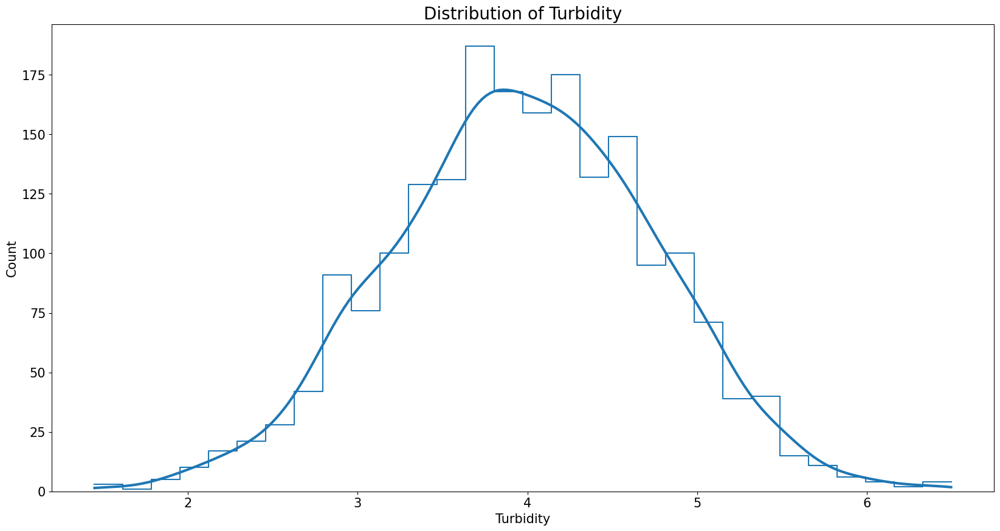

In [ ]:
fig, ax = plt.subplots(figsize=(20, 10), dpi=100)


sns.histplot(
        data=new_df,
        x="Turbidity",
        bins=30,
        #color="#F54927",
        kde=True,
        line_kws={
        'color': "#27F5B0",
        'linewidth': 3
        },
        ax=ax,

        element='step',
        fill=False

    )

ax.set_title("Distribution of Turbidity", fontsize=20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
ax.set_xlabel('Turbidity', fontsize=15)
ax.set_ylabel('Count', fontsize=15)


plt.show()

This plot represents ***normal distribution***

It has ***outliers*** in the begining and the end of the x range.

It has several ***noise*** issues where at x near 3 has a sharp increase and we can see some sawtooth in this plot.

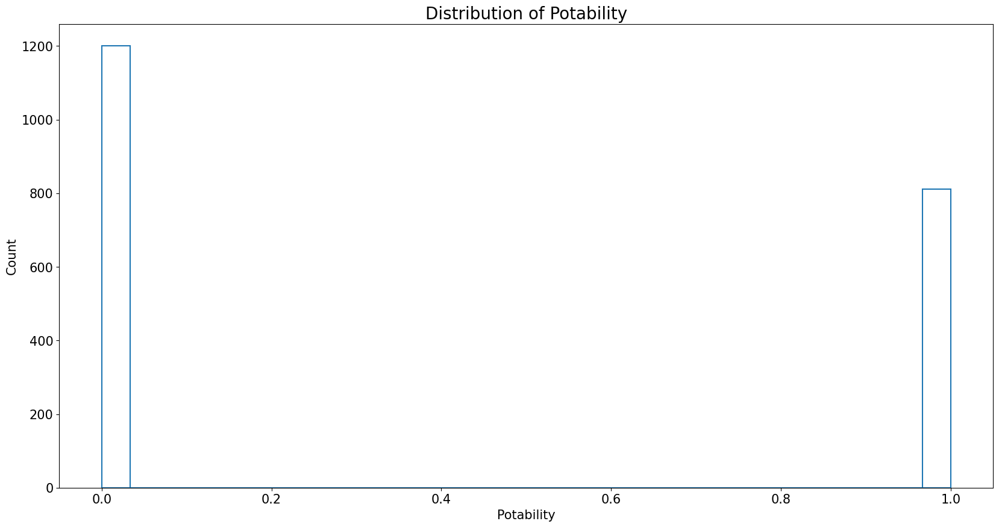

In [ ]:
fig, ax = plt.subplots(figsize=(20, 10), dpi=100)


sns.histplot(
        data=new_df,
        x="Potability",
        bins=30,
        line_kws={
        'color': "#27F5B0",
        'linewidth': 3
        },
        ax=ax,
        fill=False

    )

ax.set_title("Distribution of Potability", fontsize=20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
ax.set_xlabel('Potability', fontsize=15)
ax.set_ylabel('Count', fontsize=15)


plt.show()

This plot illustrates that we are facing an ***imbalanced target***.

**Scatter plots**

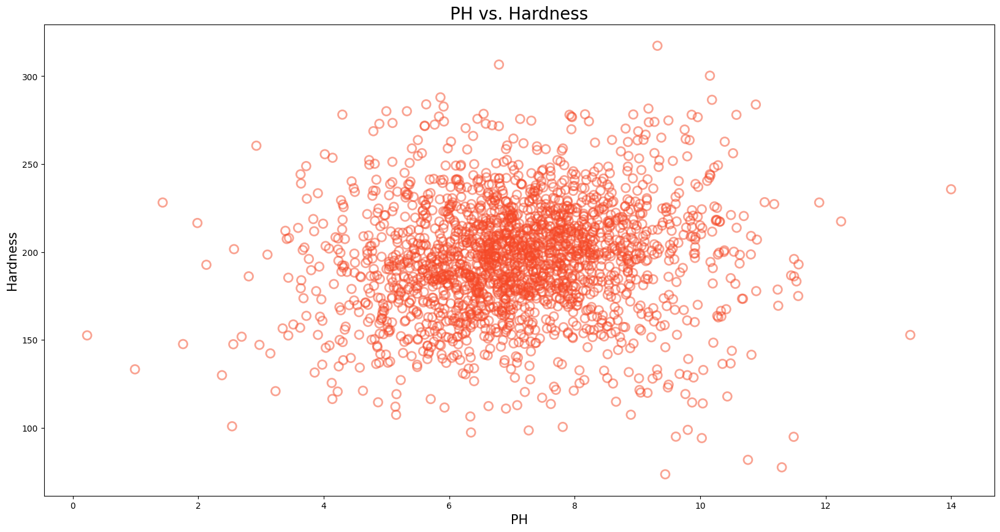

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
scatter=ax.scatter(
    new_df['ph'],
    new_df['Hardness'],
    s=100,
    alpha=0.5,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)

ax.set_title("PH vs. Hardness", fontsize=20)
ax.set_ylabel("Hardness", fontsize=15)
ax.set_xlabel("PH", fontsize=15)
plt.show()

**PH** and **Hardness** act as **independent features** in this dataset. There is no clustering, no curvature, and no positive or negative trend line linking them together.

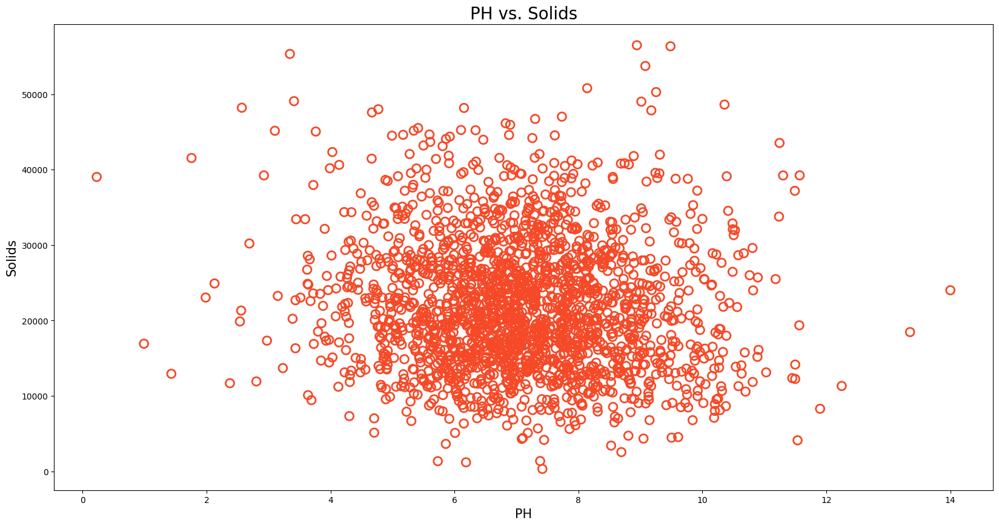

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
scatter=ax.scatter(
    new_df['ph'],
    new_df['Solids'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)

ax.set_title("PH vs. Solids", fontsize=20)
ax.set_ylabel("Solids", fontsize=15)
ax.set_xlabel("PH", fontsize=15)
plt.show()

**PH** and **Solids** are completely **independant**.

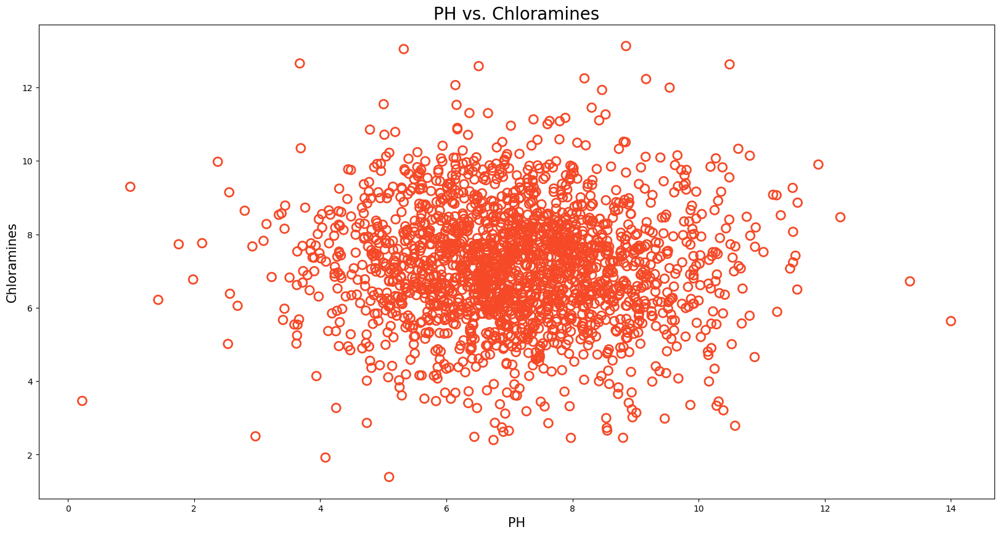

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
scatter=ax.scatter(
    new_df['ph'],
    new_df['Chloramines'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)

ax.set_title("PH vs. Chloramines", fontsize=20)
ax.set_ylabel("Chloramines", fontsize=15)
ax.set_xlabel("PH", fontsize=15)
plt.show()

**PH** and **Chloramines** are completely **independant**

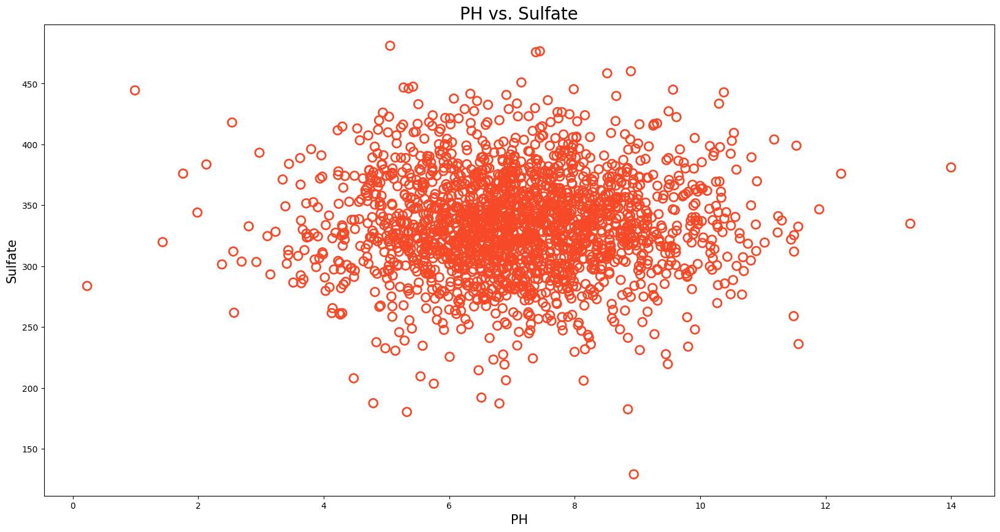

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
scatter=ax.scatter(
    new_df['ph'],
    new_df['Sulfate'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)

ax.set_title("PH vs. Sulfate", fontsize=20)
ax.set_ylabel("Sulfate", fontsize=15)
ax.set_xlabel("PH", fontsize=15)
plt.show()

**PH** and **Sulfate** are **independant**

It has one anomaly where Sulfate is even less than 150 and we may face **noise**

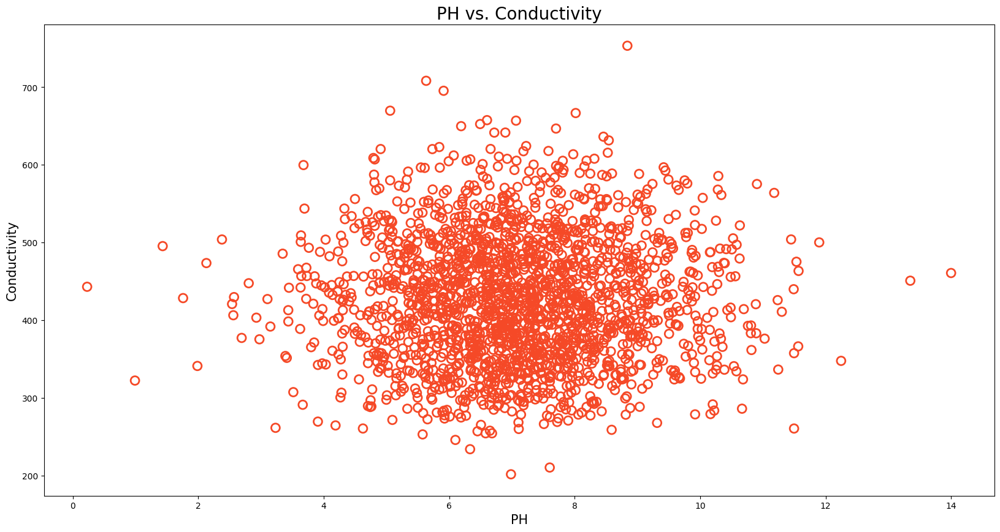

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
scatter=ax.scatter(
    new_df['ph'],
    new_df['Conductivity'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)

ax.set_title("PH vs. Conductivity", fontsize=20)
ax.set_ylabel("Conductivity", fontsize=15)
ax.set_xlabel("PH", fontsize=15)
plt.show()

**PH** and **Conductivity** are statistically **independent**

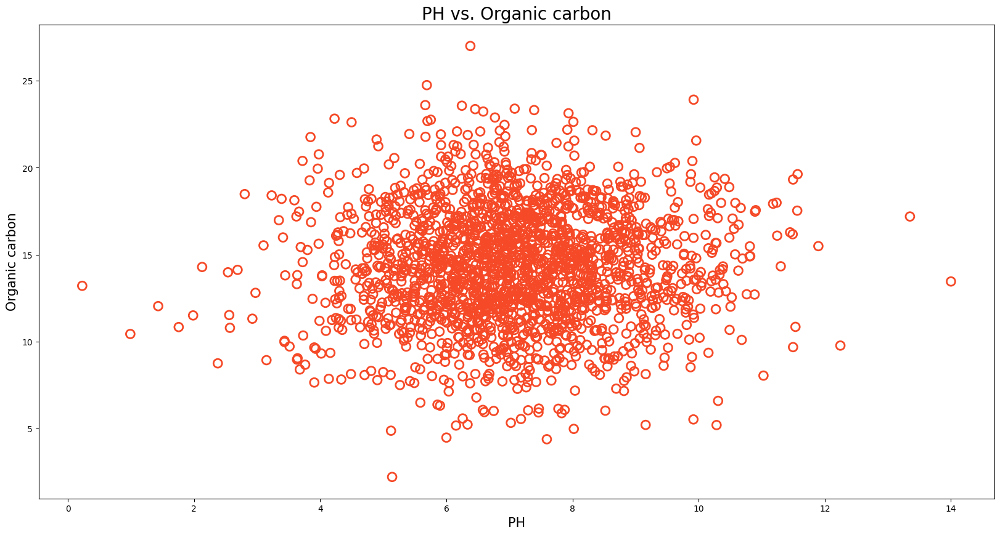

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
scatter=ax.scatter(
    new_df['ph'],
    new_df['Organic_carbon'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)

ax.set_title("PH vs. Organic carbon", fontsize=20)
ax.set_ylabel("Organic carbon", fontsize=15)
ax.set_xlabel("PH", fontsize=15)
plt.show()

**PH** and **Organic carbon** are **independant**.

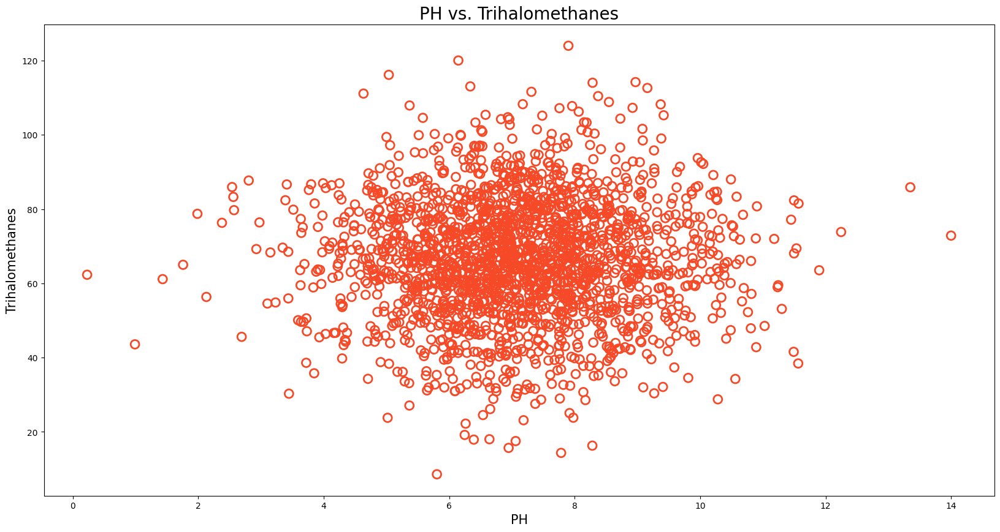

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
scatter=ax.scatter(
    new_df['ph'],
    new_df['Trihalomethanes'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)

ax.set_title("PH vs. Trihalomethanes", fontsize=20)
ax.set_ylabel("Trihalomethanes", fontsize=15)
ax.set_xlabel("PH", fontsize=15)
plt.show()

**PH** and **Trihalomethanes** are statistically **independent**.

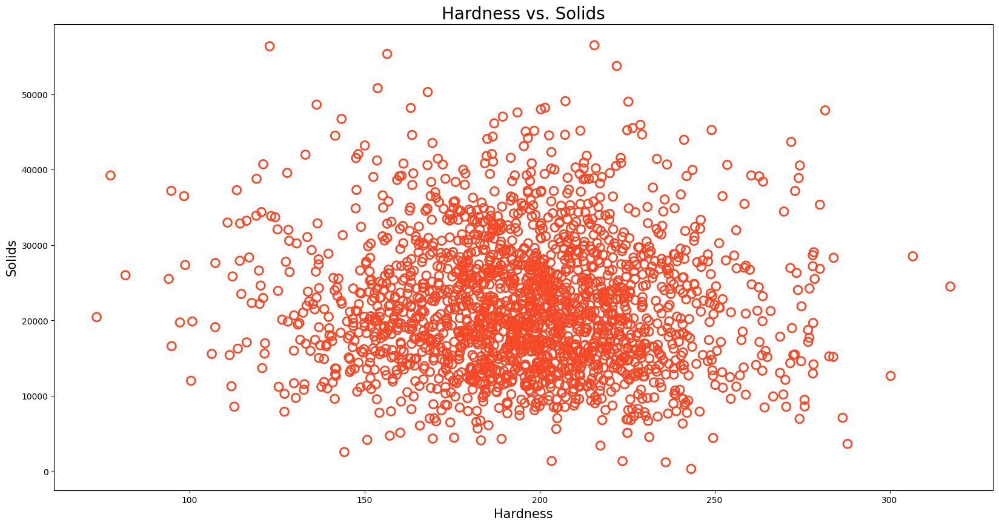

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
ax.scatter(
    new_df['Hardness'],
    new_df['Solids'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)
ax.set_title("Hardness vs. Solids", fontsize=20)
ax.set_ylabel("Solids", fontsize=15)
ax.set_xlabel("Hardness", fontsize=15)
plt.show()

In spite of mathematical stuff, Hardness and Solids are statistically independant

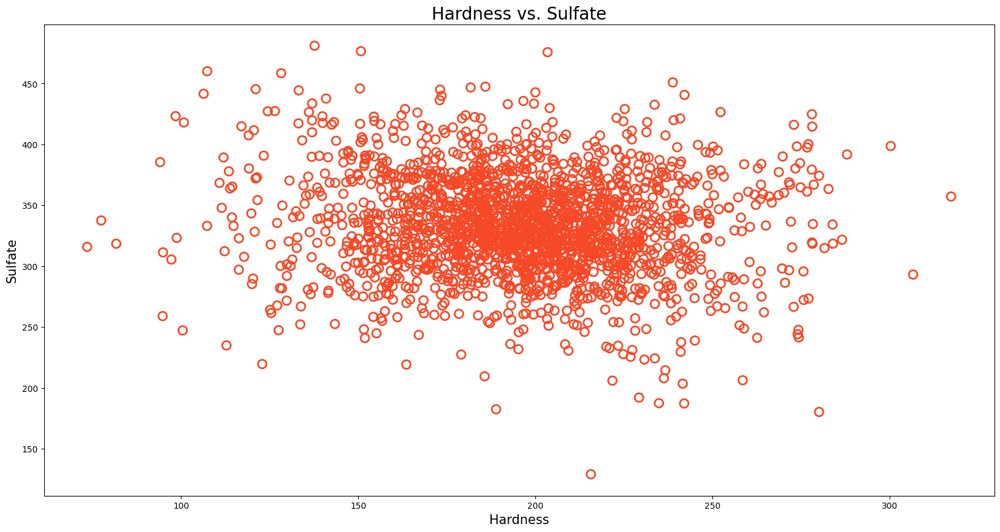

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
ax.scatter(
    new_df['Hardness'],
    new_df['Sulfate'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)
ax.set_title("Hardness vs. Sulfate", fontsize=20)
ax.set_ylabel("Sulfate", fontsize=15)
ax.set_xlabel("Hardness", fontsize=15)
plt.show()

**Hardness** and **Sulfate** are statistically **independant**

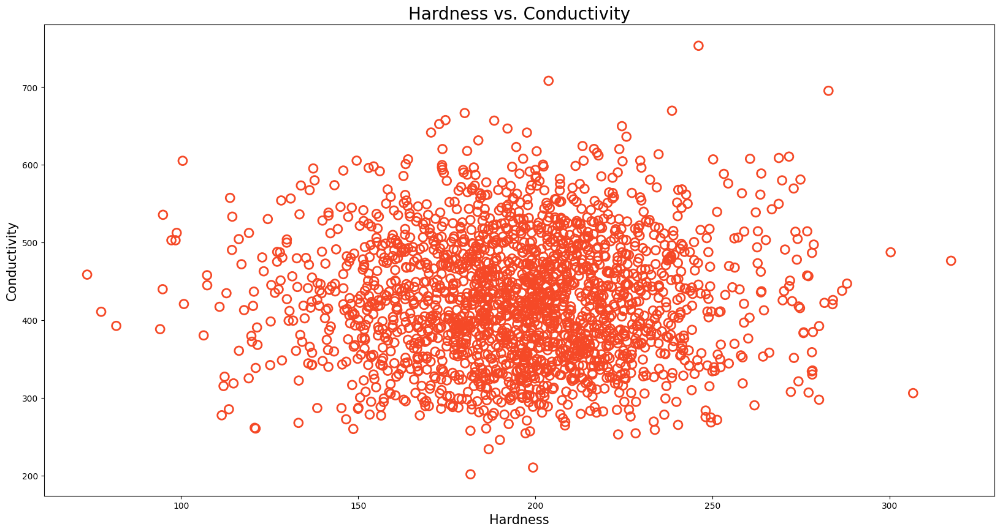

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
ax.scatter(
    new_df['Hardness'],
    new_df['Conductivity'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)
ax.set_title("Hardness vs. Conductivity", fontsize=20)
ax.set_ylabel("Conductivity", fontsize=15)
ax.set_xlabel("Hardness", fontsize=15)
plt.show()

**Hardness** and **Conductivity** are **independant**

As we mentioned in **distribution of conductivity**, there are two outliers, first the sample less than 200 and the other higher than 700

And we can see shotgun cloud that can represents noise.

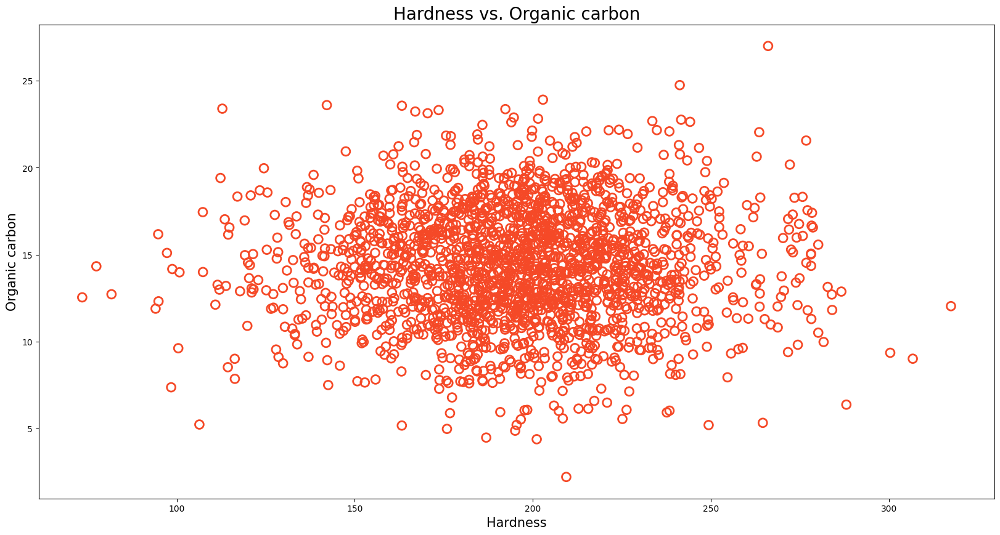

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
ax.scatter(
    new_df['Hardness'],
    new_df['Organic_carbon'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)
ax.set_title("Hardness vs. Organic carbon", fontsize=20)
ax.set_ylabel("Organic carbon", fontsize=15)
ax.set_xlabel("Hardness", fontsize=15)
plt.show()

These two are **independant** and also two samples that can be outliers.

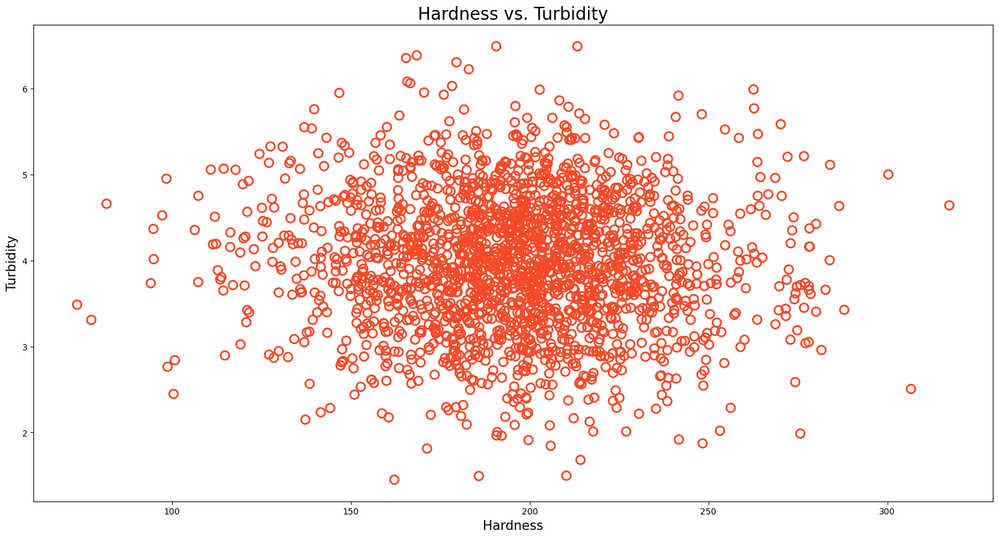

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
ax.scatter(
    new_df['Hardness'],
    new_df['Turbidity'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)
ax.set_title("Hardness vs. Turbidity", fontsize=20)
ax.set_ylabel("Turbidity", fontsize=15)
ax.set_xlabel("Hardness", fontsize=15)
plt.show()

These two features are **independant**
It shows also ***shotgun clouds*** which illustrates **noise** and we may have some dots as **outliers**

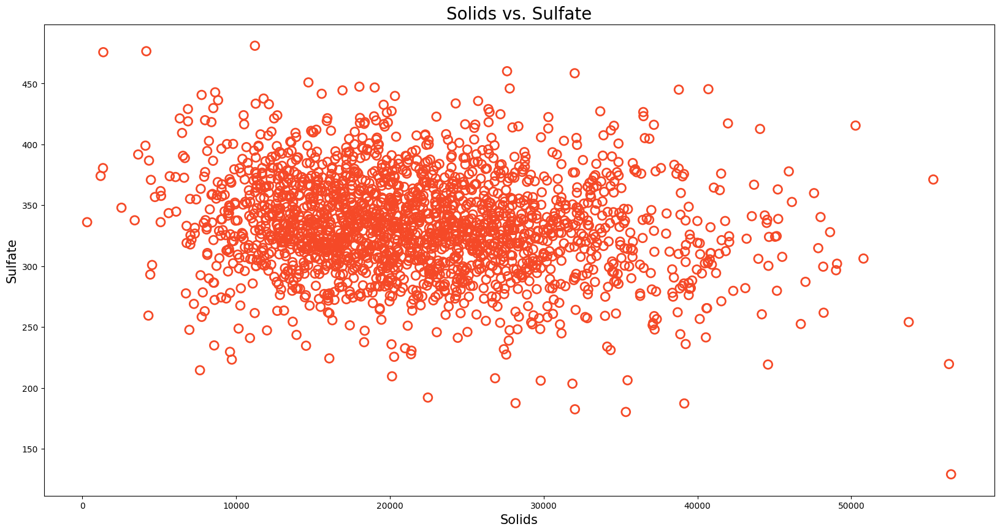

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
ax.scatter(
    new_df['Solids'],
    new_df['Sulfate'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)
ax.set_title("Solids vs. Sulfate", fontsize=20)
ax.set_ylabel("Sulfate", fontsize=15)
ax.set_xlabel("Solids", fontsize=15)
plt.show()

**Solids** and **Sulfate** are **independant**

A clear **outlier** can be seen in the right down corner of the plot.


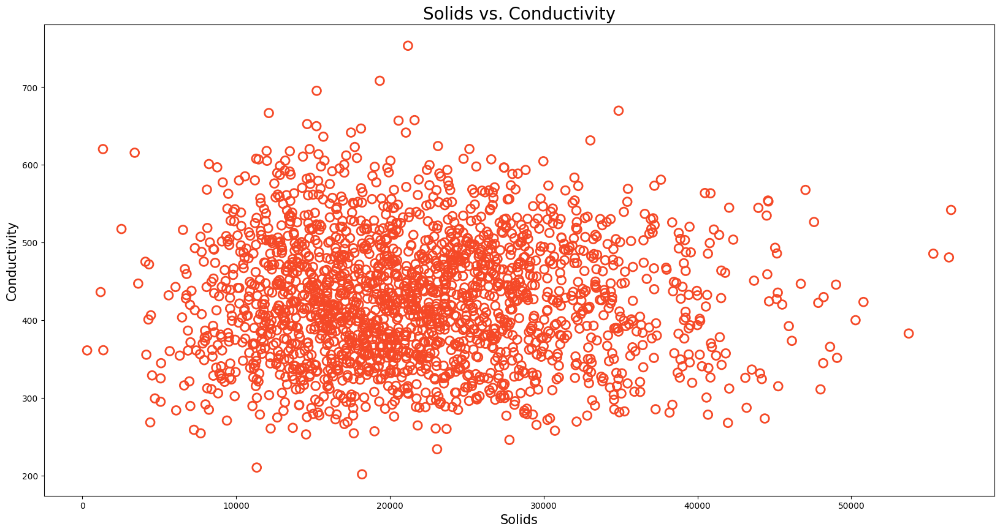

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
ax.scatter(
    new_df['Solids'],
    new_df['Conductivity'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)
ax.set_title("Solids vs. Conductivity", fontsize=20)
ax.set_ylabel("Conductivity", fontsize=15)
ax.set_xlabel("Solids", fontsize=15)
plt.show()

there is *no meaningful relation* between **Solids** and **Conductivity**, just **clouds** can be seen.

We have **outliers**.

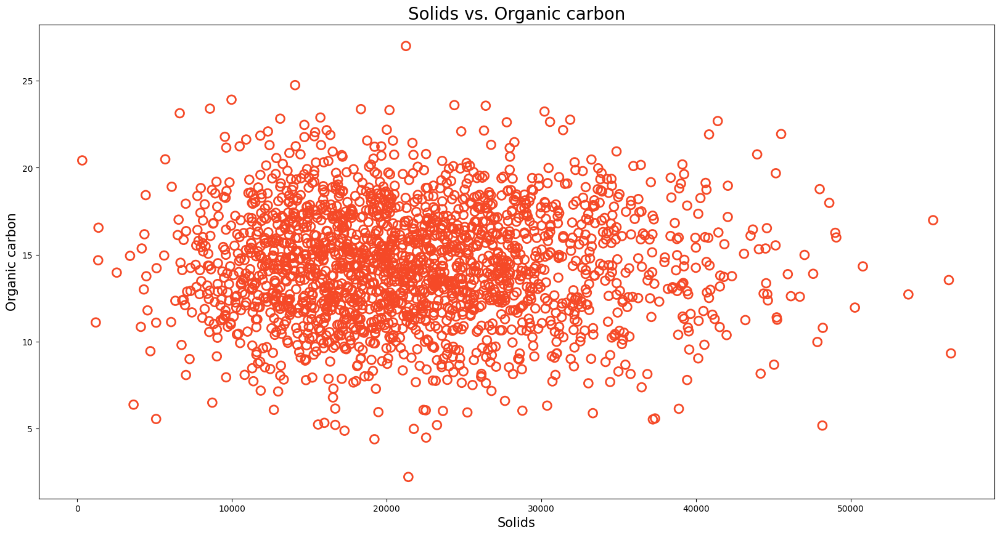

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
ax.scatter(
    new_df['Solids'],
    new_df['Organic_carbon'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)
ax.set_title("Solids vs. Organic carbon", fontsize=20)
ax.set_ylabel("Organic carbon", fontsize=15)
ax.set_xlabel("Solids", fontsize=15)
plt.show()

**Noise** is the only thing we can see in this plot.

And also some **outliers**.

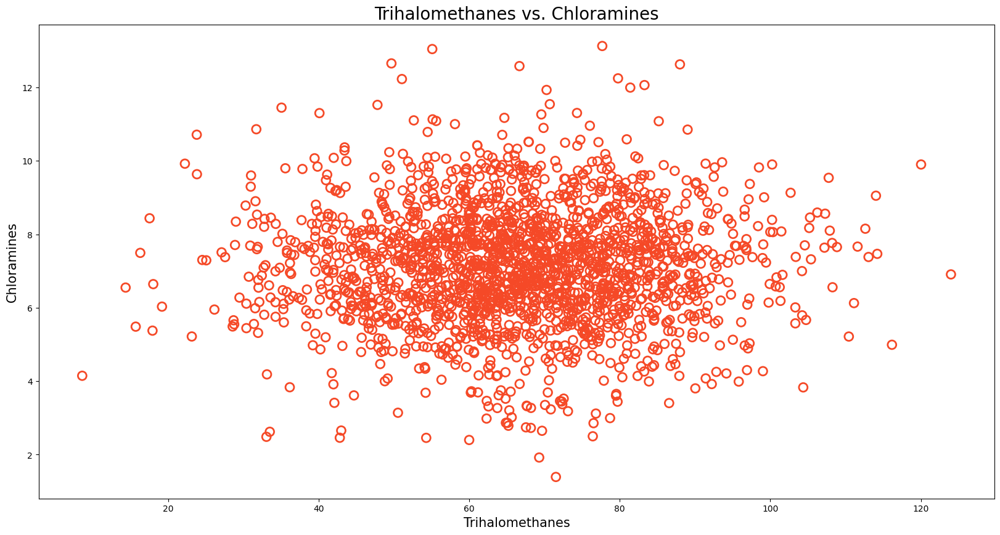

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
ax.scatter(
    new_df['Trihalomethanes'],
    new_df['Chloramines'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)
ax.set_title("Trihalomethanes vs. Chloramines", fontsize=20)
ax.set_ylabel("Chloramines", fontsize=15)
ax.set_xlabel("Trihalomethanes", fontsize=15)
plt.show()

**No** relations.

This plot shows us some **outliers**.

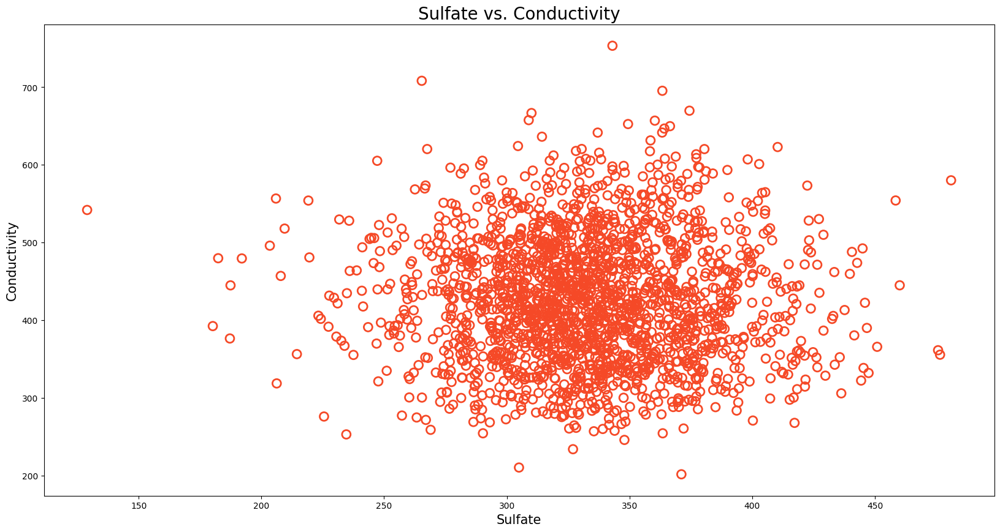

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
ax.scatter(
    new_df['Sulfate'],
    new_df['Conductivity'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)
ax.set_title("Sulfate vs. Conductivity", fontsize=20)
ax.set_ylabel("Conductivity", fontsize=15)
ax.set_xlabel("Sulfate", fontsize=15)
plt.show()

**No** relations discovered.

It has several **outliers**.

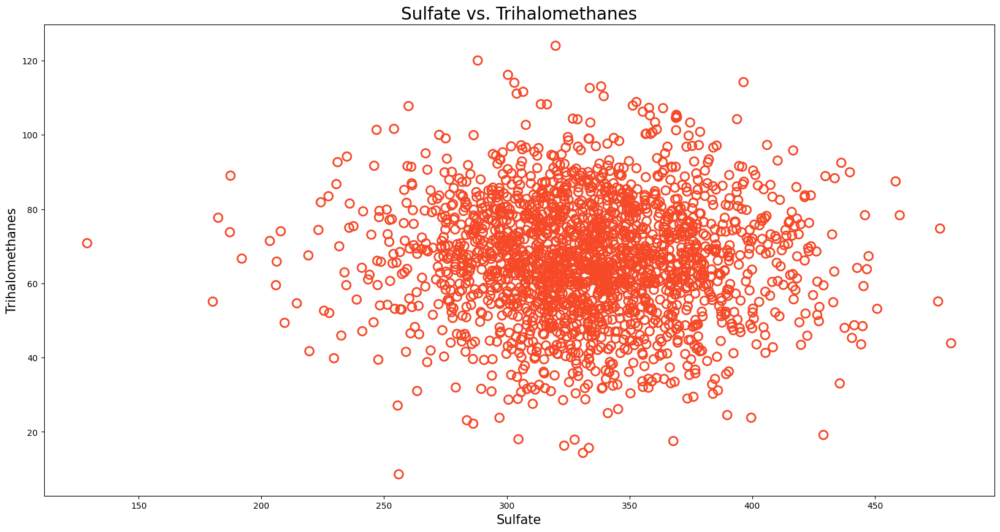

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
ax.scatter(
    new_df['Sulfate'],
    new_df['Trihalomethanes'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)
ax.set_title("Sulfate vs. Trihalomethanes", fontsize=20)
ax.set_ylabel("Trihalomethanes", fontsize=15)
ax.set_xlabel("Sulfate", fontsize=15)
plt.show()

This plot shows the **noisy relation** between these tow features.

And some **outliers** detected.

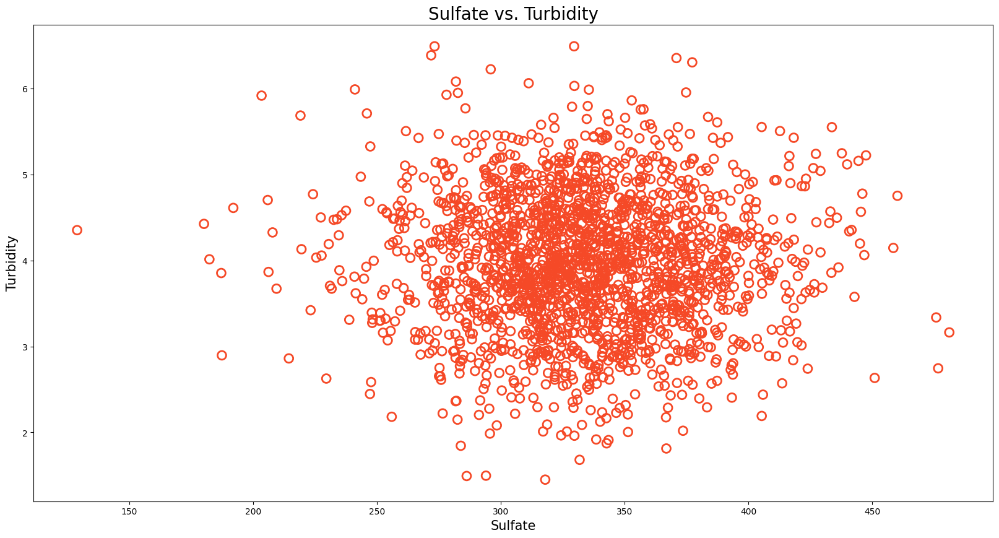

In [ ]:
fig,ax=plt.subplots(figsize=(20,10), dpi=100)
ax.scatter(
    new_df['Sulfate'],
    new_df['Turbidity'],
    s=100,
    marker="o",
    facecolors='none',
    edgecolors="#F54927",
    lw=2
)
ax.set_title("Sulfate vs. Turbidity", fontsize=20)
ax.set_ylabel("Turbidity", fontsize=15)
ax.set_xlabel("Sulfate", fontsize=15)
plt.show()

This plot can be used as an example of **noisy relation**.

it has both **noise** and **outliers**.




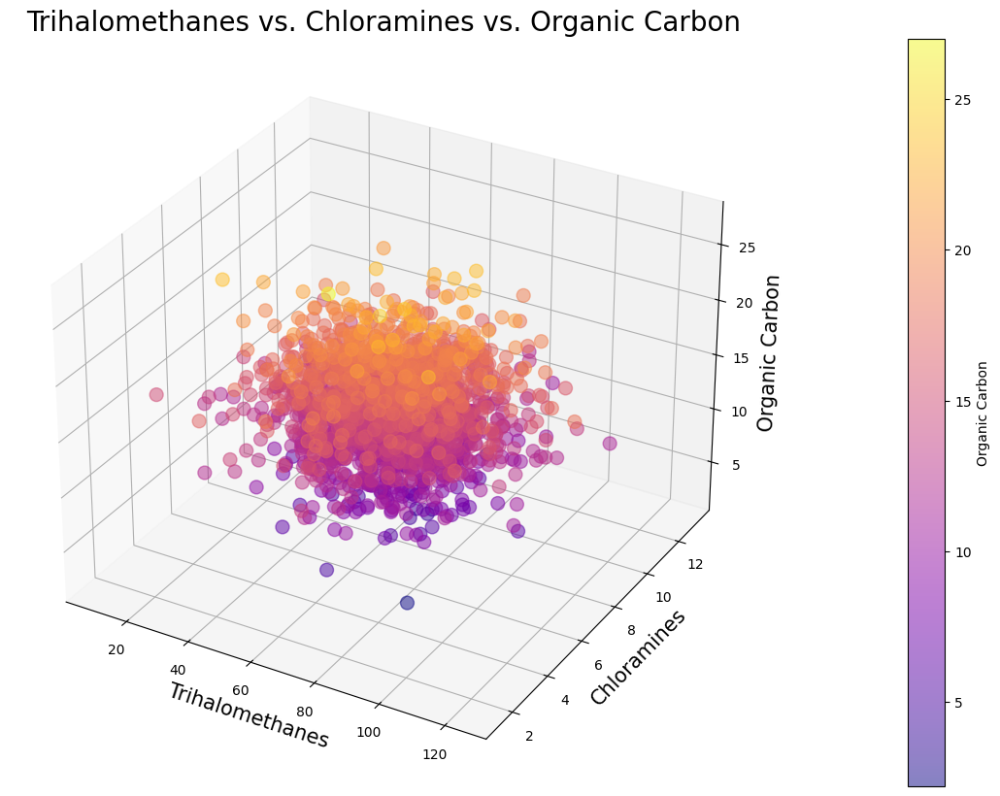

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(20, 10), dpi=100)
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    new_df['Trihalomethanes'],
    new_df['Chloramines'],
    new_df['Organic_carbon'],
    s=100,
    alpha=0.5,
    marker='o',
    c=new_df['Organic_carbon'],
    cmap='plasma'
)

ax.set_title(
    'Trihalomethanes vs. Chloramines vs. Organic Carbon',
    fontsize=20
)

ax.set_xlabel('Trihalomethanes', fontsize=15)
ax.set_ylabel('Chloramines', fontsize=15)
ax.set_zlabel('Organic Carbon', fontsize=15)

plt.colorbar(
    scatter,
    ax=ax,
    label='Organic Carbon',
    pad=0.1
)

plt.show()

Logically it should be a relation between Trihalomethanes & Chloramines & Organic carbon, but this plot illustrates that **statistically** there is ***no correlation between these three features***.

**Correlation**

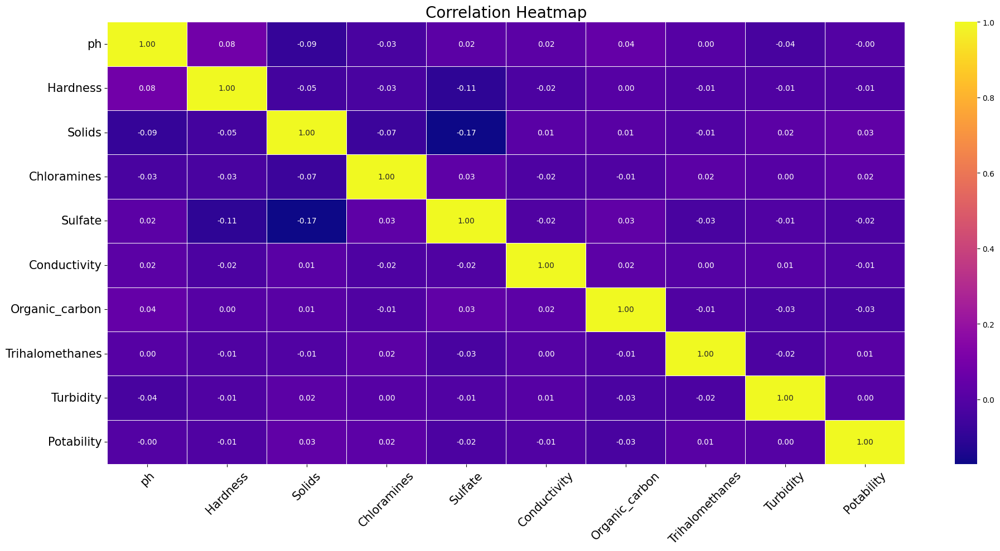

In [ ]:
corr_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(20, 10), dpi=100)

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='plasma',
    linewidths=0.5
)
plt.xticks(fontsize=15, rotation=45)
plt.yticks(fontsize=15, rotation=0)

plt.title('Correlation Heatmap', fontsize=20)
plt.tight_layout()
plt.show()

As we showed in scatter plots and the results we explained, this dataset has ***no meaningful correlations between its features***.